# Grevy's zebra body orientation during an escape response

How does a group reorient when it detects a disturbance? An approaching
human observer provides a clear event around which to compare baseline
behavior and the escape response. The case study follows 18 Grevy's zebras
(*Equus grevyi*) in a focal group at Mpala Conservancy in Laikipia, Kenya.
An overhead drone recorded three flights. The first two captured baseline
behavior, and the third included the human approach. Body orientation is
the direction from the base of the tail to the base of the neck.

The analysis asks three related questions.

- **Group mean direction.** Which way does the group typically face in
  each period?
- **Between-individual alignment.** How closely do the zebras' typical
  orientations agree with one another?
- **Within-individual concentration.** How consistently does each zebra
  face its own typical direction?

The group can turn while its members remain about as aligned as before.
A zebra can also face a consistent direction of its own even when the
group is weakly aligned. A hierarchical circular model lets us study
these patterns separately while accounting for repeated observations
of the same animals.

Drone observation methods are described by
[Koger et al. (2023)](https://doi.org/10.1111/1365-2656.13904).


## Setup

[R setup guide](https://jgraving.github.io/unwrap/getting-started-r/)


In [1]:
# Setup: check that this notebook's stack is available. The examples
# are verified against the pinned package set recorded in renv.lock, so
# this cell deliberately does not auto-install: an unpinned install
# could silently drift from the verified set. Run the one-time setup on
# the R setup page first (docs/getting-started-r.md).

required <- c("brms", "posterior", "loo", "circular", "ggplot2", "ragg", "arrow")
missing <- required[!vapply(required, requireNamespace, logical(1),
  quietly = TRUE)]
if (length(missing))
  stop("Missing R package(s): ", paste(missing, collapse = ", "),
       " - run the one-time setup on the R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

cmdstan_ok <- tryCatch(
  dir.exists(as.character(cmdstanr::cmdstan_path())),
  error = function(e) FALSE)
if (!cmdstan_ok)
  stop("cmdstanr/CmdStan is not available - run the one-time setup on the",
       " R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

In [2]:
suppressPackageStartupMessages({
    library(brms)
    library(posterior)
    library(loo)
    library(circular)
    library(ggplot2)
    library(arrow)
})

# The repository's R helpers (custom brms family + circular statistics)
# live next to the notebook; make them reachable regardless of the
# kernel's working directory.
repo_root <- if (file.exists(file.path("..", "R", "unwrap_family.R"))) ".." else
    if (file.exists(file.path("R", "unwrap_family.R"))) "." else
    stop("Run this notebook from notebooks_r/ or from the repository root.")
source(file.path(repo_root, "R", "unwrap_family.R"))
source(file.path(repo_root, "R", "unwrap_functions.R"))
source(file.path(repo_root, "notebooks_r", "zebra_posthoc.R"))
source(file.path(repo_root, "notebooks_r", "zebra_plots.R"))

# The figure code writes to the repository-relative figures directory.
FIG_DIR <- file.path(repo_root, "figures", "zebra_escape")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)
theme_set(theme_minimal(base_size = 12))

# Without X11/cairo (most server R installs) the default device cannot
# rasterise, so each figure renders to a PNG through ragg and displays
# inline; a vector PDF is saved alongside as the portable copy.
show_figure <- function(plot, name, width, height, res = 110) {
  file <- file.path(FIG_DIR, paste0(name, ".png"))
  ragg::agg_png(file, width = width, height = height, units = "in",
                res = res)
  print(plot)
  invisible(dev.off())
  IRdisplay::display_png(file = file)
  invisible(NULL)
}


SEED <- 42
set.seed(SEED)
quick_run <- Sys.getenv("UNWRAP_R_QUICK") == "1"
CHAINS <- 4L
# Hierarchical models need longer adaptation and more retained draws than
# the introductory GLM. Quick mode keeps the full data and model, shortening only
# sampling and Monte Carlo plotting/bootstrapping budgets.
ITER <- if (quick_run) 6000L else 8000L
WARMUP <- if (quick_run) 2250L else 3000L
ADAPT_DELTA <- 0.97
# The tighter adapt_delta protects the grouped concentration geometry;
# these are execution budgets, not a claim of verified convergence.

c(R = as.character(getRversion()),
  brms = as.character(packageVersion("brms")),
  cmdstanr = as.character(packageVersion("cmdstanr")),
  posterior = as.character(packageVersion("posterior")),
  loo = as.character(packageVersion("loo")),
  circular = as.character(packageVersion("circular")),
  ggplot2 = as.character(packageVersion("ggplot2")),
  ragg = as.character(packageVersion("ragg")),
  arrow = as.character(packageVersion("arrow")))


Loading required package: cmdstanr



This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /home/jake/.cmdstan/cmdstan-2.40.0



- CmdStan version: 2.40.0



R          brms      cmdstanr     posterior           loo 
      "4.5.3"      "2.23.0"       "0.9.0"       "1.7.1" "2.10.1.9000" 
     circular       ggplot2          ragg         arrow 
      "0.5.2"       "4.0.3"       "1.5.2"      "26.0.0"

## Reading the figures

Orange marks the pre-stimulus baseline, and purple marks the period
after the approach began. Compare the two periods at the group level,
then follow the same zebra across periods to see how individual
responses vary.


In [3]:
# Display conventions from the Python figures; the required palette is set
# in the data cell. These helpers change only plotting copies of summaries.
condition_shapes <- c("pre-approach" = 15, "post-approach" = 16)
ppc_shapes <- c("pre-approach / data bootstrap" = 0,
  "pre-approach / posterior" = 15,
  "post-approach / data bootstrap" = 1,
  "post-approach / posterior" = 16)
ppc_display <- function(x) {
  angular <- grepl("direction", x$quantity, fixed = TRUE)
  x[angular, c("mean", "low", "high")] <-
    x[angular, c("mean", "low", "high")] * 180 / pi
  x$quantity <- sub("(rad)", "(deg)", x$quantity, fixed = TRUE)
  x$condition <- factor(x$condition, levels = condition_labels)
  x
}
ppc_display_support <- function(x) {
  # Reference axes cover a full angular turn and the mathematical R domain.
  # Train each facet without censoring intervals that cross the angular seam.
  lo <- hi <- x[!duplicated(x[c("quantity", "condition")]), , drop = FALSE]
  angular <- grepl("direction", lo$quantity, fixed = TRUE)
  lo$mean <- ifelse(angular, -180, 0)
  hi$mean <- ifelse(angular, 180, 1)
  rbind(lo, hi)
}

save_figure <- function(plot, name, width = 8, height = 4) {
  ggsave(file.path(FIG_DIR, paste0(name, ".pdf")), plot,
         width = width, height = height)
  show_figure(plot, name, width, height)
}

# Same published source files as the Python loaders; keep their local
# checkout under the repository root, reachable from notebooks_r/ too.
# An existing checkout can be supplied through UNWRAP_DATA_ROOT.
data_root <- Sys.getenv("UNWRAP_DATA_ROOT",
                        unset = file.path(repo_root, "unwrap-data"))
ensure_data <- function(subdir) {
  target <- file.path(data_root, subdir)
  if (!dir.exists(target)) {
    if (!dir.exists(data_root)) {
      status <- system2("git", c("clone", "--depth", "1",
        "--filter=blob:none", "--sparse",
        "https://github.com/jgraving/unwrap-data.git", shQuote(data_root)))
      if (status != 0L) stop("Could not fetch the published study data.")
    }
    # Sparse checkout downloads only this study; later notebooks may add
    # their own subdirectory to the same checkout without replacing it.
    status <- system2("git", c("-C", shQuote(data_root),
                              "sparse-checkout", "add", subdir))
    if (status != 0L) stop("Could not materialize the study subdirectory.")
  }
  stopifnot(dir.exists(target))
  target
}


## Summarize repeated body orientations

Successive frames often show nearly the same orientation. We summarize
each zebra's observations in non-overlapping 10-second windows to reduce
short-term dependence. Each window contributes a circular mean. For
example, orientations of 359° and 1° average to 0° on the circle.

We compare windows before the onset of the approach with those after
it begins. We include zebras observed in both periods so that each animal
contributes to the comparison. The windows give us repeated measurements
within each of the 18 zebras.


In [4]:
data_dir <- ensure_data("zebra_bearings")
data <- as.data.frame(arrow::read_parquet(file.path(data_dir,
                                              "zebra_bearings_blocks.parquet")))
needed <- c("Track", "Observation", "Condition", "HeadingRadians", "PostStimulus")
stopifnot(all(needed %in% names(data)), !anyNA(data[needed]))
data$Track <- factor(data$Track)
data$PostStimulus <- as.integer(data$PostStimulus)
data$HeadingRadians <- mod_circular(data$HeadingRadians)
condition_labels <- c("pre-approach", "post-approach")
condition_colors <- c("pre-approach" = "#E69F00", "post-approach" = "#7B3294")
data$condition <- factor(data$PostStimulus, levels = 0:1, labels = condition_labels)
stopifnot(nlevels(data$Track) == 18L,
          all(table(data$Track, data$PostStimulus) > 0),
          all(is.finite(data$HeadingRadians)))
head(data)


,Track,Observation,Condition,HeadingRadians,PostStimulus,condition
,<fct>,<chr>,<chr>,<dbl>,<int>,<fct>
1,observation088-0,observation088,pre-approach,1.324933,0,pre-approach
2,observation088-0,observation088,pre-approach,1.455568,0,pre-approach
3,observation088-0,observation088,pre-approach,1.578286,0,pre-approach
4,observation088-0,observation088,pre-approach,1.412140,0,pre-approach
5,observation088-0,observation088,pre-approach,1.778967,0,pre-approach
6,observation088-0,observation088,pre-approach,2.116859,0,pre-approach


## Model direction and concentration together

The von Mises distribution describes angles around a mean direction
$\mu$. Its concentration $\kappa$ measures how tightly angles cluster
around that direction. We let the approach affect both quantities so
the model can distinguish turning from a change in directional
consistency.

The hierarchical model estimates a group baseline and a group change
for both mean direction and concentration. Each zebra can differ from
the group in where it starts and how it responds. Partial pooling lets
the zebras inform one another's estimates while retaining individual
differences. This is especially helpful when a zebra has few
observations in one period.

Before seeing the data, we give nearly equal prior weight to all
baseline directions and give smaller turns more weight than larger
ones. The priors for individual deviations are centered on the group
pattern. The data help estimate how much zebras differ from that
pattern.


In [5]:
# Preserve independent circular intercept and slope deviations. brms's
# ordinary (1 + PostStimulus | Track) mu term would impose Gaussian effects.
# Following the Rmd, represent them as nonlinear coefficient vectors.
form_vonmises <- bf(HeadingRadians ~ mu,
  nlf(mu ~ beta0 + bias0 + PostStimulus * bias1),
  beta0 ~ 1 + PostStimulus,
  bias0 ~ 0 + Track,
  bias1 ~ 0 + Track,
  kappa ~ 0 + Intercept + PostStimulus + (1 + PostStimulus || Track),
  family = unwrap_von_mises)

# One LogNormal(log(30), 0.5) hyperprior for each direction-effect vector,
# as in Python. Direct positive parameters need no softplus Jacobian.
stan_direction_priors <- stanvar(scode = "
  real<lower=0> kmu_intercept;
  real<lower=0> kmu_slope;
", block = "parameters") + stanvar(scode = "
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) {
      lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    }
    return lp;
  }
", block = "functions")
prior_vonmises <- (
  # The direction coefficients are unconstrained reals, matching the
  # Python twin's circ_mod parameterization: its von Mises coefficient
  # priors are periodic over the real line and carry no +-pi bounds.
  # Each coefficient's prior is its von Mises log density, added as an
  # explicit target term (the weak-kappa 1e-6 intercept term is
  # effectively flat over any 2*pi window; a uniform prior is NOT used:
  # bounded uniform boxes pin NUTS chains against the +-pi walls). The
  # generated Stan for this prior set is free of brms's default Gaussian
  # on the direction coefficients (verified at build time in the fit
  # cell).
  set_prior("target += unwrap_von_mises_lpdf(b_beta0[1] | 0, 1e-6)", check = FALSE) +
  set_prior("target += unwrap_von_mises_lpdf(b_beta0[2] | 0, 2)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_bias0 | 0, kmu_intercept)",
            check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_bias1 | 0, kmu_slope)",
            check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_intercept | log(30), 0.5)",
            check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_slope | log(30), 0.5)",
            check = FALSE) +
  prior("normal(log(exp(2) - 1), 1)", class = "b", dpar = "kappa",
        coef = "Intercept") +
  prior("normal(0, 2)", class = "b", dpar = "kappa",
        coef = "PostStimulus") +
  prior("normal(0, 2)", class = "sd", dpar = "kappa")
)
# EQUIVALENCE NOTE: || removes brms's default intercept/slope correlation;
# the Python priors are separate independent effects, with no LKJ term.
# Gaussian kappa effects use brms's non-centered parameterization and
# positive sd bounds turn normal(0, 2) into HalfNormal(2).
# The nonlinear mu vectors retain centered von Mises effects, not normal
# random effects. Verify their generated names/bounds/priors when baking.
prior_vonmises

prior,class,coef,group,resp,dpar,nlpar,lb,ub,tag,source
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"target += unwrap_von_mises_lpdf(b_beta0[1] | 0, 1e-6)",,,,,,,,,,user
"target += unwrap_von_mises_lpdf(b_beta0[2] | 0, 2)",,,,,,,,,,user
"target += unwrap_von_mises_vect_lpdf(b_bias0 | 0, kmu_intercept)",,,,,,,,,,user
"target += unwrap_von_mises_vect_lpdf(b_bias1 | 0, kmu_slope)",,,,,,,,,,user
"target += lognormal_lpdf(kmu_intercept | log(30), 0.5)",,,,,,,,,,user
"target += lognormal_lpdf(kmu_slope | log(30), 0.5)",,,,,,,,,,user
"normal(log(exp(2) - 1), 1)",b,Intercept,,,kappa,,NA,NA,,user
"normal(0, 2)",b,PostStimulus,,,kappa,,NA,NA,,user
"normal(0, 2)",sd,,,,kappa,,NA,NA,,user


## Estimate the posterior

Bayesian inference combines these priors with the observed orientations.
The posterior carries uncertainty about the group response and each
zebra's response into the comparisons that follow.


In [6]:
# Inspect the generated Stan before sampling: every direction
# coefficient must be an UNCONSTRAINED real (the Python circ_mod
# geometry - periodic von Mises priors, no +-pi bounds) and each
# coefficient's von Mises prior must appear as a target term.
stan_code <- make_stancode(form_vonmises, data = data,
  prior = prior_vonmises,
  stanvars = stan_unwrap_fun + modulo_circular_fun + stan_direction_priors)
stopifnot(grepl("vector[K_beta0] b_beta0;", stan_code, fixed = TRUE),
          grepl("vector[K_bias0] b_bias0;", stan_code, fixed = TRUE),
          grepl("vector[K_bias1] b_bias1;", stan_code, fixed = TRUE),
          !grepl("uniform_lpdf", stan_code, fixed = TRUE),
          grepl("kmu_intercept", stan_code, fixed = TRUE),
          grepl("unwrap_von_mises_vect_lpdf", stan_code, fixed = TRUE))

# The von Mises priors and the likelihood depend on the direction
# coefficients only modulo 2*pi, so the total posterior is a countable
# family of 2*pi-equivalent classes with equal mass; a chain converged
# within the class it starts in. With the default start, different
# chains can land in different classes and read as non-mixed even
# though every chain is individually converged. All chains therefore
# start in one shared class - the prior-preferred vicinity of the
# origin, jitter too small to cross into a neighbouring class. This
# changes only the sampler's path, never the posterior.
n_track <- length(levels(data$Track))
stopifnot(n_track == 18L)
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.25, 0.25)
  list(b_beta0 = as.numeric(j(2)),
    b_bias0 = as.numeric(j(n_track)),
    b_bias1 = as.numeric(j(n_track)),
    kmu_intercept = 30, kmu_slope = 30)
}
fit <- brm(form_vonmises, data = data,
  stanvars = stan_unwrap_fun + modulo_circular_fun + stan_direction_priors,
  prior = prior_vonmises, backend = "cmdstanr",
  chains = CHAINS, iter = ITER, warmup = WARMUP, cores = CHAINS,
  seed = SEED,
  init = lapply(seq_len(CHAINS), function(k) mk_init(SEED + k)),
  control = list(adapt_delta = ADAPT_DELTA))

Start sampling



Init values were only set for a subset of parameters. 
Missing init values for the following parameters:
 - chain 1: b_kappa, sd_1, z_1
 - chain 2: b_kappa, sd_1, z_1
 - chain 3: b_kappa, sd_1, z_1
 - chain 4: b_kappa, sd_1, z_1

To disable this message use options(cmdstanr_warn_inits = FALSE).




Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 8000 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 8000 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 8000 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 8000 [  0%]  (Warmup) 
Chain 2 Iteration:  100 / 8000 [  1%]  (Warmup) 
Chain 1 Iteration:  100 / 8000 [  1%]  (Warmup) 
Chain 3 Iteration:  100 / 8000 [  1%]  (Warmup) 
Chain 4 Iteration:  100 / 8000 [  1%]  (Warmup) 
Chain 4 Iteration:  200 / 8000 [  2%]  (Warmup) 
Chain 1 Iteration:  200 / 8000 [  2%]  (Warmup) 
Chain 2 Iteration:  200 / 8000 [  2%]  (Warmup) 
Chain 3 Iteration:  200 / 8000 [  2%]  (Warmup) 
Chain 4 Iteration:  300 / 8000 [  3%]  (Warmup) 
Chain 1 Iteration:  300 / 8000 [  3%]  (Warmup) 
Chain 3 Iteration:  300 / 8000 [  3%]  (Warmup) 
Chain 4 Iteration:  400 / 8000 [  5%]  (Warmup) 
Chain 2 Iteration:  300 / 8000 [  3%]  (Warmup) 
Chain 1 Iteration:  400 / 8000 [  5%]  (Warmup) 
Chain 3 Iteration:  400 / 8000 [  5%]  (Warmup) 
Chain 4 Iteration:  500 / 800

Loading required namespace: rstan



## Check the posterior estimates

Before interpreting the biological patterns, check whether the sampling
chains give consistent estimates. Divergent transitions warn that the
sampler may have missed parts of the posterior. $\hat{R}$ near 1 suggests
that the chains agree, and effective sample size indicates how much
information their correlated draws provide. Review any flagged
estimates before drawing conclusions.


In [7]:

available <- posterior::variables(posterior::as_draws_array(fit))
circular_parameters <- available[grepl("^b_(beta0|bias0|bias1)_", available)]
summary_frame <- diagnose_fit(fit, circular_parameters)
summary_frame


Divergences: not retained in this fit object (see R-hat/ESS below).


parameter,mean,sd,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
b_beta0_Intercept,1.825078867,0.08556858,1.0000,5745.5
b_beta0_PostStimulus,2.209297172,0.11995104,1.0001,8460.1
b_bias0_Trackobservation088M0,-0.040170310,0.13336549,1.0000,12130.9
b_bias0_Trackobservation088M1,0.199330604,0.13859479,1.0002,12327.6
b_bias0_Trackobservation088M10,-0.033094821,0.20186266,1.0000,20709.9
b_bias0_Trackobservation088M11,0.456951476,0.12042121,1.0000,9617.3
b_bias0_Trackobservation088M12,0.069378475,0.10523761,1.0000,7890.5
b_bias0_Trackobservation088M13,-0.002803311,0.12907207,1.0000,11094.5
b_bias0_Trackobservation088M14,-0.445817703,0.14264853,1.0001,12561.4


In [8]:
summary_frame[!is.finite(summary_frame$rhat) | summary_frame$rhat >= 1.01 |
              !is.finite(summary_frame$ess_bulk) | summary_frame$ess_bulk <= 400, ]


parameter,mean,sd,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>


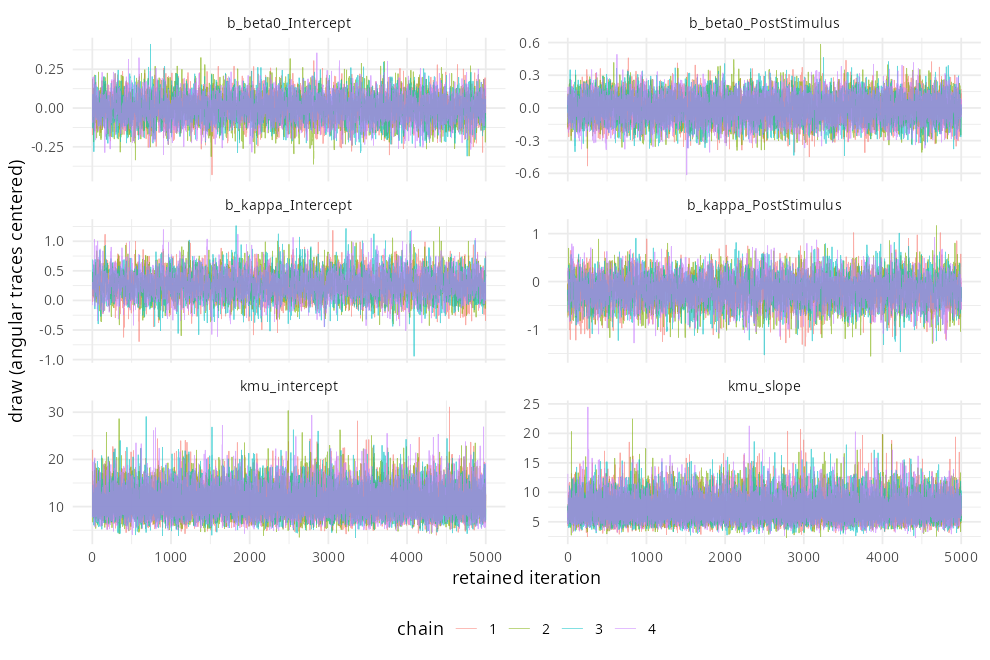

In [9]:
trace_parameters <- c("b_beta0_Intercept", "b_beta0_PostStimulus",
  "b_kappa_Intercept", "b_kappa_PostStimulus", "kmu_intercept", "kmu_slope")

p_trace <- trace_plot(fit, trace_parameters, circular_parameters)
save_figure(p_trace, "trace", 9, 6)


## Interpret the group and individual responses

Start with the group mean direction. Each zebra contributes equally
to the circular average of the estimated individual directions.
The shift between periods shows that the group reoriented after the
approach began.

Next, compare between-individual alignment. Imagine each zebra's mean
direction as an arrow of equal length. When the arrows point in similar
directions, their average has a length closer to 1. When the arrows
cancel, the average length is closer to 0. Alignment is broadly similar
across periods, even though the group's mean direction shifts.

At the individual level, the circular curves show uncertainty about
each zebra's mean direction, and the points show its observed circular
averages. The paired estimates show how consistently the same zebra
faced its own mean direction in each period. We report the mean
resultant length implied by its concentration $\kappa$, on a scale
from 0 to 1. Higher values indicate more consistent orientation.
The paired estimates and their 95% highest-density intervals show
that within-individual concentration varies substantially among zebras.


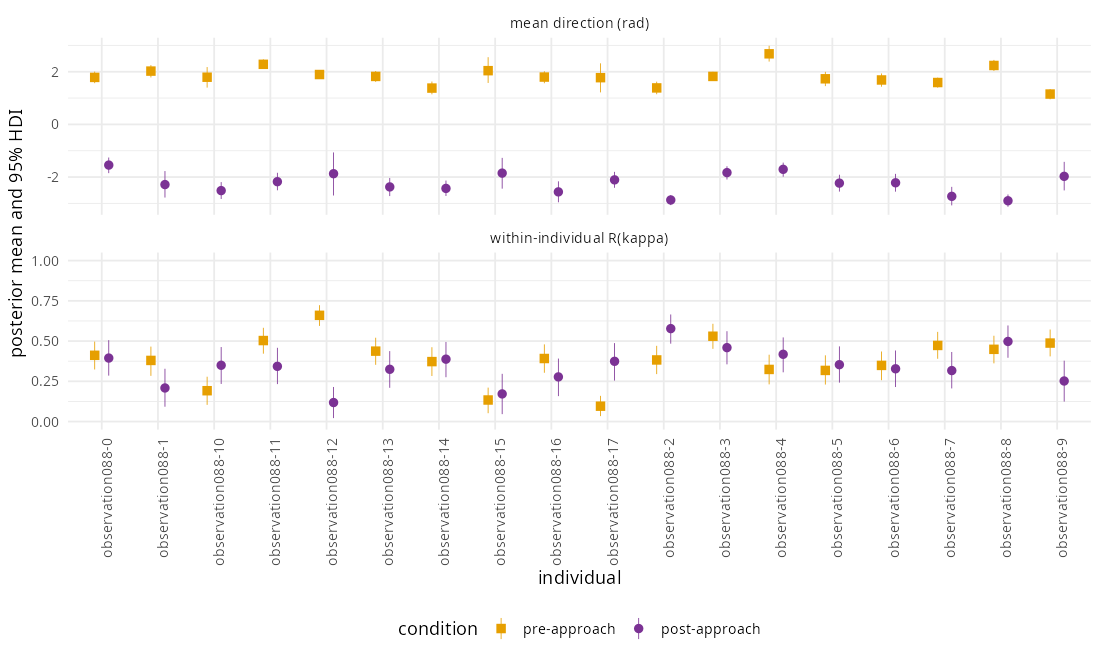

In [10]:


# Draw x individual-condition matrices from the fitted model; the
# per-draw direction and concentration matrices feed the summary panels,
# the alignment statistic and the PPC below (twin of zebra_posthoc.py).
posterior <- posterior_directions(fit, data, condition_labels)
prediction_data <- posterior$prediction_data
mu <- posterior$mu
kappa <- posterior$kappa
J <- posterior$J
pre <- posterior$pre
post <- posterior$post
group_alignment <- posterior$group_alignment
individual_summary <- posterior$individual_summary
# Keep the per-track tile layout, but retain Python's condition markers
# and the full mathematical R(kappa) domain in the concentration facet.
r_support <- data.frame(id = individual_summary$id[1],
  quantity = "within-individual R(kappa)", mean = c(0, 1))
p_individual <- individual_plot(individual_summary, condition_colors) +
  aes(shape = condition) + scale_shape_manual(values = condition_shapes) +
  geom_blank(data = r_support, aes(id, mean), inherit.aes = FALSE)
save_figure(p_individual, "individual_posteriors", 10, 6)


Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.


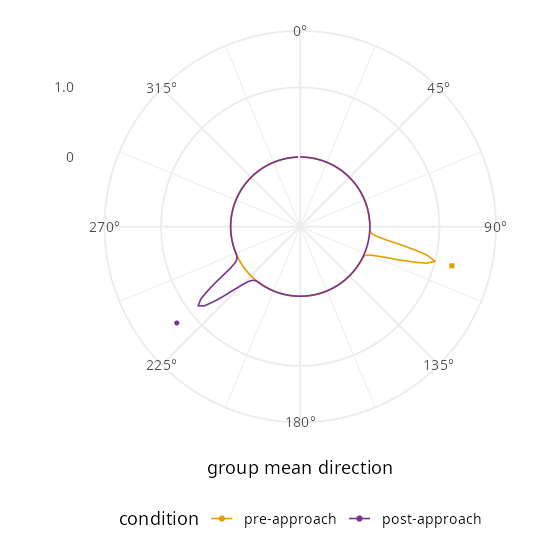

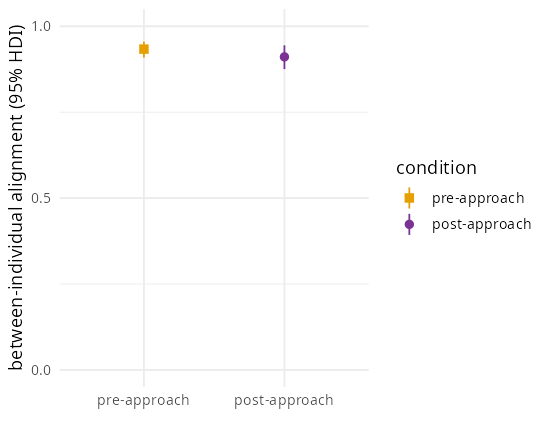

Coordinate system already present.
ℹ Adding new coordinate system, which will replace the existing one.


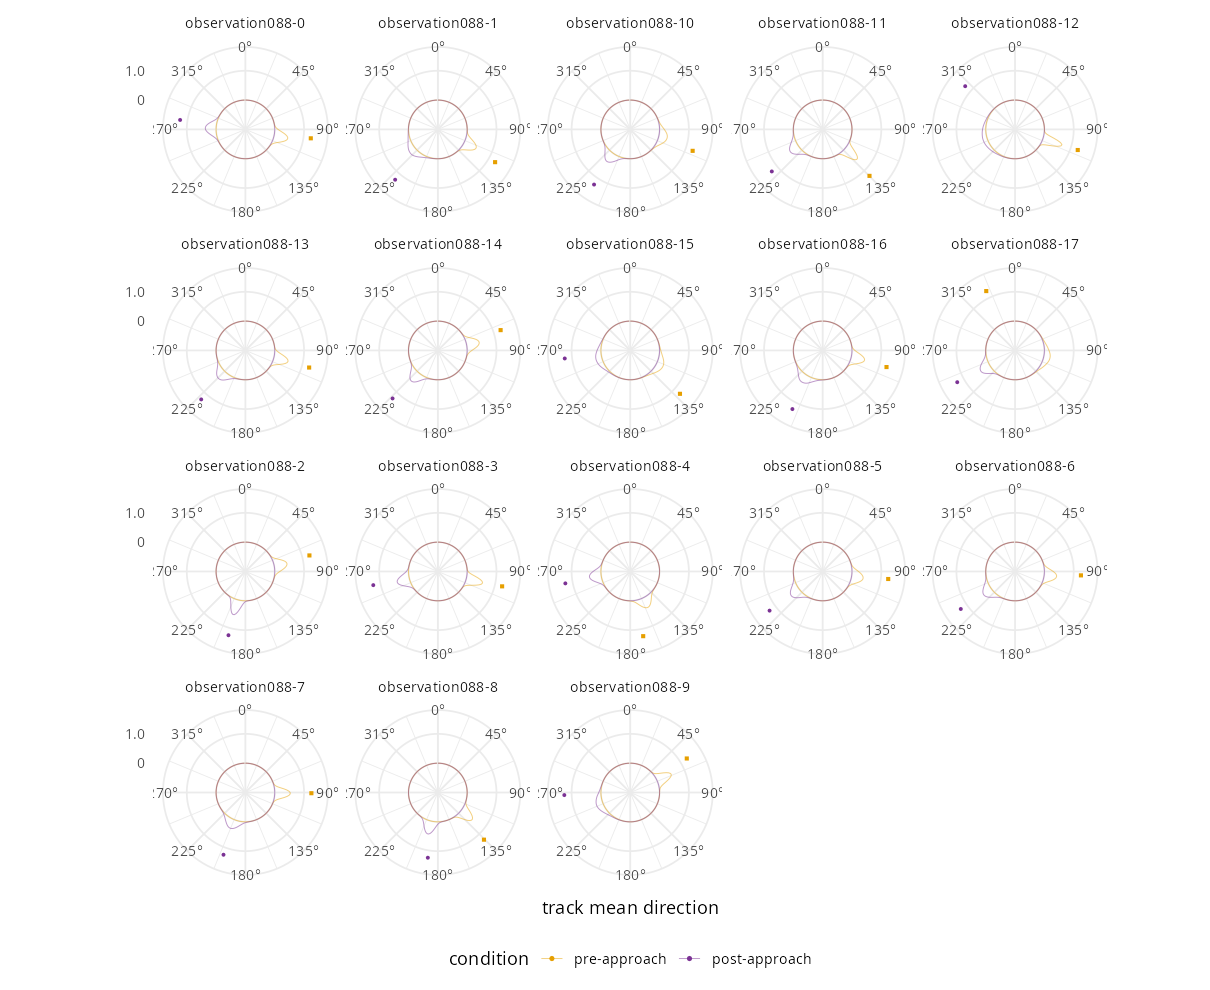

In [11]:
# As in Python's main summary, group direction here is the equal-track
# circular mean of conditional track directions. The PPC below instead
# uses population fixed effects for its group-direction comparison.
group_mu <- cbind(apply(mu[, pre, drop = FALSE], 1, circ_mean),
                   apply(mu[, post, drop = FALSE], 1, circ_mean))
# Polar KDE panels follow the Python twin (zebra_plots.py, plot_summary):
# the plotted radius is 1 + kde/max_kde, where max_kde is the shared peak
# of all group and per-track curves; the inner ring (radius 1, labelled
# "0") therefore sits at density zero instead of the origin, the outer
# ring (radius 2, "1.0") at the shared peak. 0 degrees is at the top and
# the angle axis runs clockwise with a label every 45 degrees;
# empirical circular means sit at fixed radius 2.25, away from the curves.
theta <- seq(-pi, pi, length.out = 201)
group_kde <- do.call(rbind, lapply(1:2, function(c) {
  data.frame(theta = theta %% (2 * pi),
    density = vapply(theta, function(t) mean(exp(vm_logpdf(t, group_mu[, c], 500))), numeric(1)),
    condition = factor(condition_labels[c], levels = condition_labels))
}))
track_kde <- do.call(rbind, lapply(seq_len(nrow(prediction_data)), function(j) {
  data.frame(theta = theta %% (2 * pi),
    density = vapply(theta, function(t) mean(exp(vm_logpdf(t, mu[, j], 300))), numeric(1)),
    Track = prediction_data$Track[j], condition = prediction_data$condition[j])
}))
max_kde <- max(group_kde$density, track_kde$density)
group_kde$r <- 1 + group_kde$density / max_kde
track_kde$r <- 1 + track_kde$density / max_kde
empirical_group <- do.call(rbind, lapply(1:2, function(c) data.frame(
  theta = circ_mean(group_mu[, c]) %% (2 * pi), r = 2.25,
  condition = factor(condition_labels[c], levels = condition_labels),
  shape = if (c == 2L) "filled circle" else "filled square")))
p_group_mu <- polar_direction_plot(group_kde, empirical_group,
  "group mean direction", condition_colors) +
  # ggplot2's zero start is north and direction = 1 is clockwise.
  coord_polar(start = 0, direction = 1) +
  scale_shape_manual(values = c("filled square" = 15, "filled circle" = 16))
save_figure(p_group_mu, "group_direction", 5, 5)
alignment_df <- do.call(rbind, lapply(1:2, function(c) {
  data.frame(condition = factor(condition_labels[c], levels = condition_labels),
    as.list(interval_row(group_alignment[, c])))
}))
p_alignment <- alignment_plot(alignment_df, condition_colors) +
  aes(shape = condition) + scale_shape_manual(values = condition_shapes) +
  scale_x_discrete(limits = condition_labels) +
  # Python explicitly uses the full resultant-length domain, not a zoom.
  scale_y_continuous(limits = c(0, 1), breaks = c(0, 0.5, 1))
save_figure(p_alignment, "group_alignment", 5, 4)

# Per-track polar direction posteriors, with empirical circular means.
empirical <- do.call(rbind, lapply(split(data, list(data$Track, data$condition),
  drop = TRUE), function(g) data.frame(Track = g$Track[1],
    condition = g$condition[1], theta = circ_mean(g$HeadingRadians) %% (2 * pi),
    r = 2.25,
    shape = if (g$condition[1] == condition_labels[2]) "filled circle" else
      "filled square")))
p_track_mu <- polar_direction_plot(track_kde, empirical,
  "track mean direction", condition_colors, track = TRUE) +
  coord_polar(start = 0, direction = 1) +
  scale_shape_manual(values = c("filled square" = 15, "filled circle" = 16))
save_figure(p_track_mu, "track_direction_polar", 11, 9)


## Check the circular summaries against the observations

Do the fitted directions and concentrations agree with the patterns
we can estimate from the observations? Open markers show bootstrap
summaries. For the group comparison, we resample zebras and then
windows within them, respecting the repeated measurements. The
individual comparisons resample windows within each zebra and period.
Filled markers show the corresponding summaries of the fitted
posterior, with the group direction based on the population effects.

Compare the estimates and their 95% intervals for group direction,
between-individual alignment, individual direction, and
within-individual concentration. Broad agreement shows that the fit
captures these features of the observations. A systematic discrepancy
would show which part of the response deserves closer inspection.


Scale for shape is already present.
Adding another scale for shape, which will replace the existing scale.


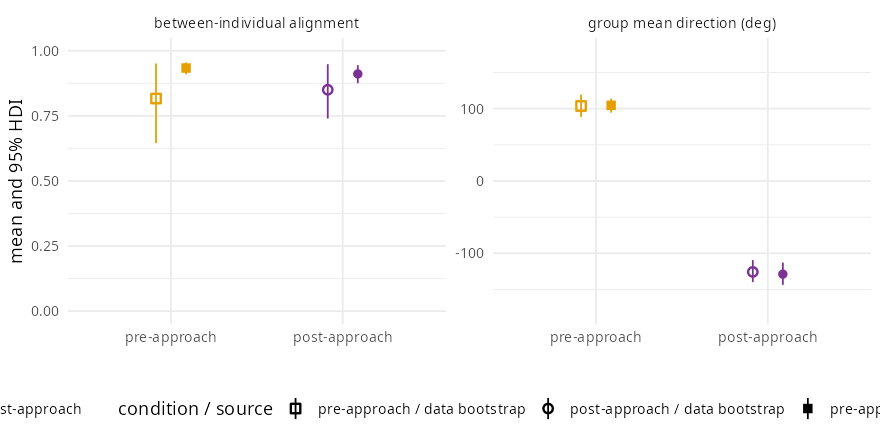

Scale for shape is already present.
Adding another scale for shape, which will replace the existing scale.


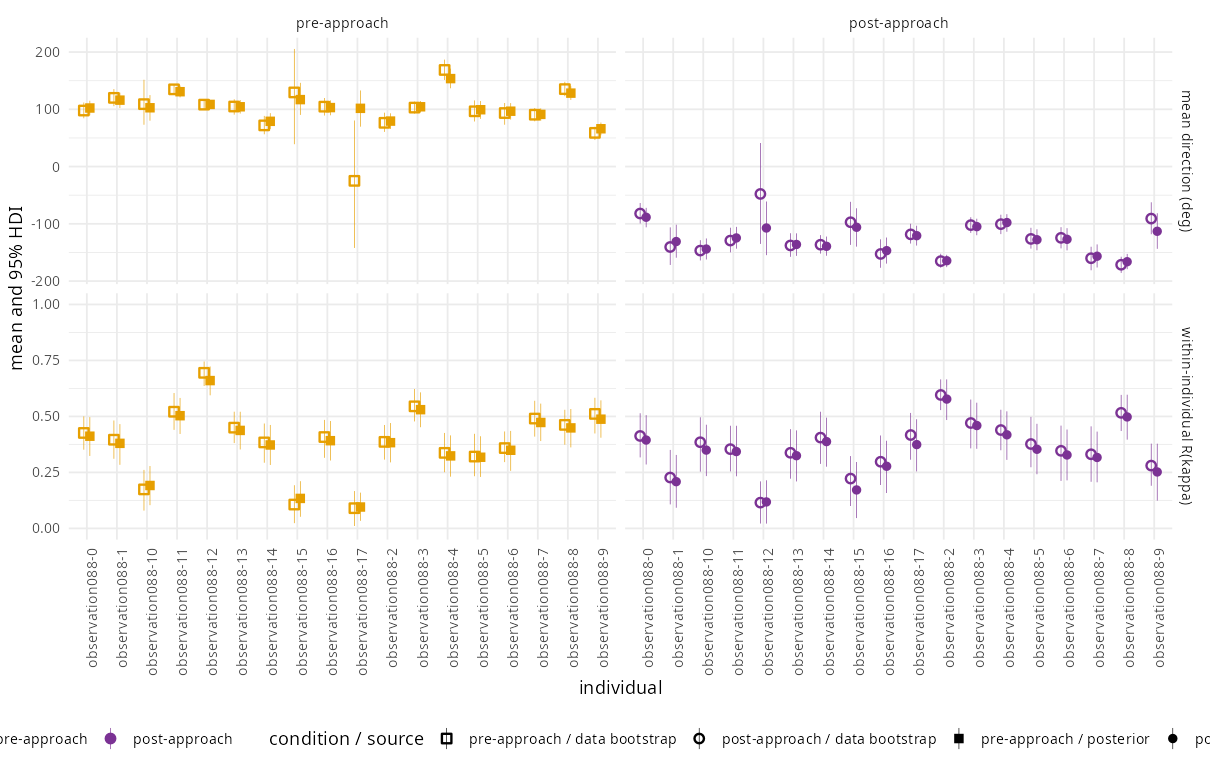

In [12]:
# Python's supplemental PPC compares data bootstraps with fitted response
# parameters (not with a new stochastic dataset). Reproduce that check,
# then add a conventional replicated-data check below.
B_GROUP <- if (quick_run) 200L else 2000L
B_INDIV <- if (quick_run) 150L else 1500L
ys <- lapply(seq_len(nrow(prediction_data)), function(j) {
  data$HeadingRadians[as.character(data$Track) ==
    as.character(prediction_data$Track[j]) &
    data$PostStimulus == prediction_data$PostStimulus[j]]
})
stopifnot(all(lengths(ys) > 0L))
# The data-bootstrap vs posterior comparison (Python's supplemental PPC)
# runs in the sourced posthoc script; the seed stays here.
set.seed(SEED + 10L)
ppc_boot <- ppc_bootstrap_stats(fit, prediction_data, ys, J,
  B_GROUP, B_INDIV, condition_labels, group_alignment, individual_summary)
ppc_group_display <- ppc_display(ppc_boot$ppc_group)
p_group_ppc <- group_ppc_plot(ppc_group_display, condition_colors) +
  aes(shape = interaction(condition, source, sep = " / ")) +
  scale_shape_manual(values = ppc_shapes, name = "condition / source") +
  scale_x_discrete(limits = condition_labels) +
  geom_blank(data = ppc_display_support(ppc_group_display),
    aes(condition, mean), inherit.aes = FALSE)
save_figure(p_group_ppc, "ppc_group", 8, 4)

ppc_individual_display <- ppc_display(ppc_boot$ppc_individual)
p_ind_ppc <- individual_ppc_plot(ppc_individual_display) +
  # Colour encodes condition; open/filled markers encode data/posterior.
  aes(colour = condition,
    shape = interaction(condition, source, sep = " / "), group = source) +
  scale_colour_manual(values = condition_colors, breaks = condition_labels) +
  scale_shape_manual(values = ppc_shapes, name = "condition / source") +
  geom_blank(data = ppc_display_support(ppc_individual_display),
    aes(id, mean), inherit.aes = FALSE)
save_figure(p_ind_ppc, "ppc_individual", 11, 7)


### Check concentration in replicated observations

Would the fitted model generate about as much directional consistency
as we observed? We draw new sets of orientations for each zebra and
period, matching the observed sample sizes. We then compare the
resultant lengths of the observed and simulated sets. This check
allows for the variation expected in a new set of observations as
well as uncertainty about the fitted directions and concentrations.


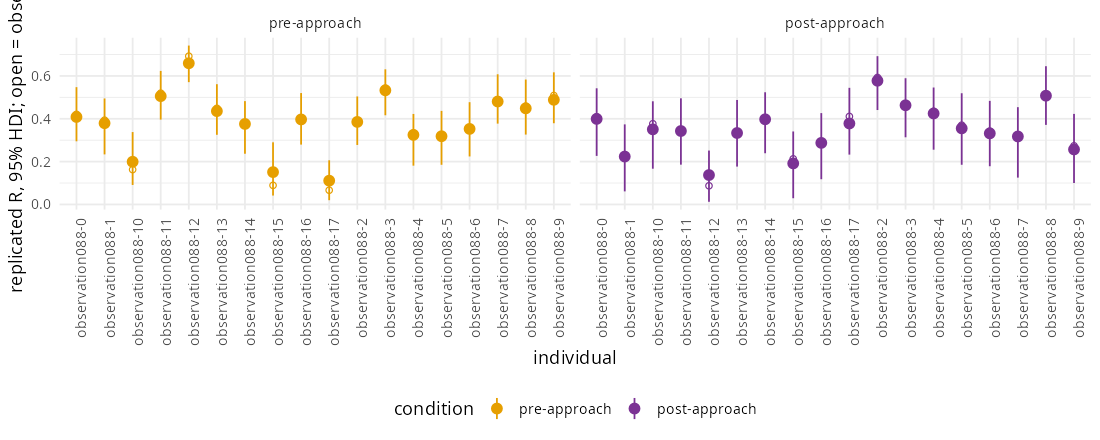

In [13]:
# Same observed sample sizes, each animal's own conditional likelihood.
# Limit simulation draws only; MCMC fitting still uses the budgets above.
set.seed(SEED + 20L)
draw_ids <- sample.int(nrow(mu), min(nrow(mu), if (quick_run) 100L else 400L))
rep_stats <- replicated_stats(mu, kappa, ys, draw_ids, prediction_data)
p_replicates <- replicated_r_plot(rep_stats, condition_colors)
save_figure(p_replicates, "ppc_replicated", 10, 4)
